# HridayTwin: walkthrough of the cleaned dataset and results
AMLBT course project · Dhruvik Sorathiya, Kruparth Pandya · Goa Institute of Management

This notebook reads the **cleaned modelling table** (`data/processed/model_table.csv.gz`) written by `python run_pipeline.py`, re-checks the headline comparison (fused EHR + home data vs EHR only) with the same patient-grouped cross-validation, and shows the saved results. All data are synthetic.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from hridaytwin import model as M
df = pd.read_csv(ROOT / 'data/processed/model_table.csv.gz')
print(df.shape, '| patients:', df.patient_id.nunique(), '| base rate: %.3f' % df.y.mean())

(23710, 83) | patients: 1200 | base rate: 0.045


## 1. Labels
One row per patient per weekly check-in. `y` = any adverse event in the next 14 days; `y_<type>` = that event type.

In [2]:
ycols = [c for c in df.columns if c.startswith('y_')]
df[['y'] + ycols].agg(['sum', 'mean']).T.rename(columns={'sum': 'positive rows', 'mean': 'rate'}).round(4)

,positive rows,rate
y,1065.0,0.0449
y_severe_hypoglycaemia,133.0,0.0056
y_hyperglycaemic_crisis,260.0,0.0110
y_hypertensive_emergency,209.0,0.0088
y_acute_cv_event,478.0,0.0202


## 2. Feature groups and missingness
Missing home readings are kept as missing; the gradient-boosted trees route them natively and count features tell the model when data went silent.

In [3]:
# features only: exclude the label columns (y, y_<type>, days_to_event), exactly as model.evaluate does
feat_cols = [c for c in df.columns if not c.startswith('y') and c != 'days_to_event']
sets = M.feature_sets(feat_cols)
print({k: len(v) for k, v in sets.items()})
stream = [c for c in sets['fused'] if c not in sets['ehr_only']]
df[stream].isna().mean().sort_values(ascending=False).head(10).round(3).rename('share missing')

{'ehr_only': 27, 'stream_only': 32, 'fused': 59, 'fused_plus_twin_state': 75}


gmin_min7         0.782
gmin_m28          0.782
glucose_trend7    0.198
glucose_m7        0.136
glucose_max7      0.136
sbp_trend7        0.100
glucose_sd14      0.074
sbp_m7            0.054
sbp_max7          0.054
dbp_m7            0.054
Name: share missing, dtype: float64

## 3. Re-check: fused vs EHR-only (5-fold GroupKFold by patient)

In [4]:
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
folds = list(GroupKFold(n_splits=5).split(df, df.y, df.patient_id))
rows = []
for name in ['ehr_only', 'fused']:
    p = M.oof_scores(df, sets[name], folds)
    rows.append({'model': name, 'AUROC': roc_auc_score(df.y, p), 'AUPRC': average_precision_score(df.y, p)})
pd.DataFrame(rows).round(3)

,model,AUROC,AUPRC
0,ehr_only,0.708,0.096
1,fused,0.727,0.112


Compare with `model/metrics.json` (fused 0.726, EHR-only 0.708). The folds and seeds are fixed; the saved table is rounded to 4 decimals, so the third decimal can differ slightly.

## 4. Saved results from the full pipeline

In [5]:
m = json.loads((ROOT / 'model/metrics.json').read_text())
pd.DataFrame(m['variants']).T[['auroc', 'auprc', 'brier', 'ece']].sort_values('auroc', ascending=False)

,auroc,auprc,brier,ece
fused,0.7257,0.1107,0.04163,0.0053
fused_logistic,0.7172,0.1062,NaN,NaN
fused_plus_twin_state,0.7088,0.1062,0.04184,0.0068
ehr_only,0.7084,0.0956,0.04235,0.0104
stream_only,0.6754,0.0977,0.04207,0.0072
clinical_rules,0.6146,0.0716,NaN,NaN


In [6]:
pd.DataFrame({k: {'delta': v['delta'], 'ci95': v['ci95'], 'p': v['p_value']} for k, v in m['paired_deltas'].items()}).T

,delta,ci95,p
fused_vs_ehr_only,0.0173,"[0.0041, 0.0319]",0.008
fused_vs_stream_only,0.0503,"[0.0336, 0.0656]",0.001
fused_vs_fused_plus_twin_state,0.0169,"[0.0066, 0.0276]",0.001
fused_vs_fused_logistic,0.0085,"[-0.0051, 0.0214]",0.226
fused_vs_clinical_rules,0.1111,"[0.0889, 0.1323]",0.001


In [7]:
pd.DataFrame({k: {'fused': v['fused_auroc'], 'ehr_only': v['ehr_only_auroc'], 'p': v['delta_vs_ehr']['p_value']}
              for k, v in m['event_types'].items()}).T

,fused,ehr_only,p
severe_hypoglycaemia,0.9427,0.9068,0.002
hyperglycaemic_crisis,0.8582,0.8465,0.164
hypertensive_emergency,0.8880,0.8839,0.564
acute_cv_event,0.7113,0.7162,0.544


In [8]:
pd.Series(m['operating_point'])

alert_budget_per_patient_week    0.1000
threshold                        0.0941
sensitivity                      0.2910
ppv                              0.1310
base_rate                        0.0449
lift_over_base_rate              2.9100
median_lead_time_days            7.0000
dtype: float64

## 5. Figures

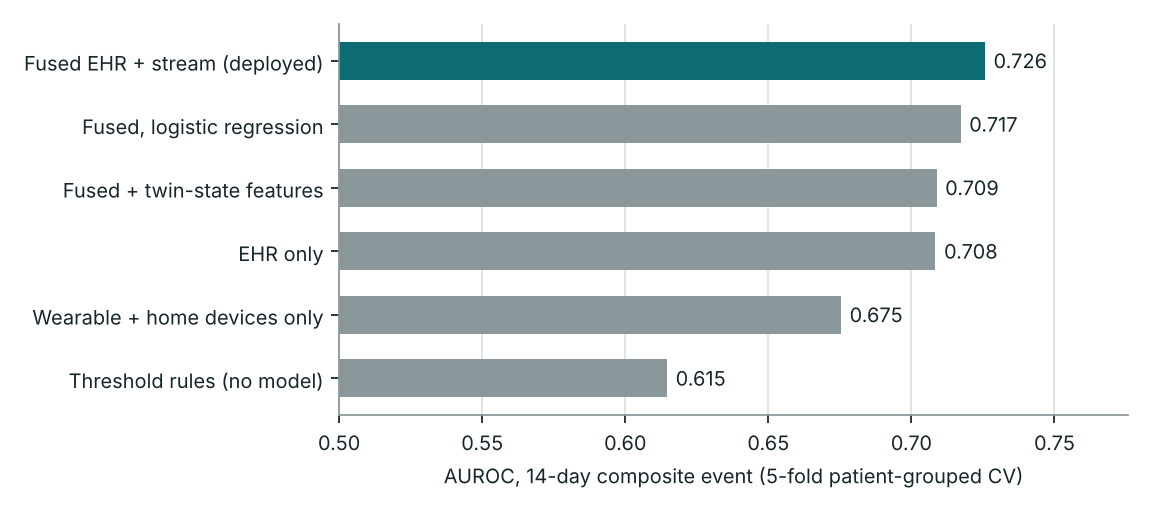

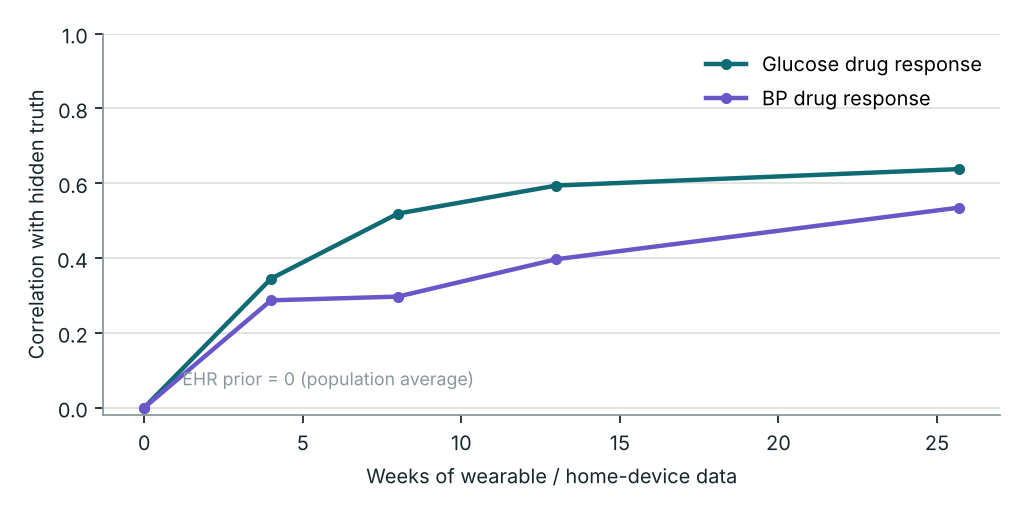

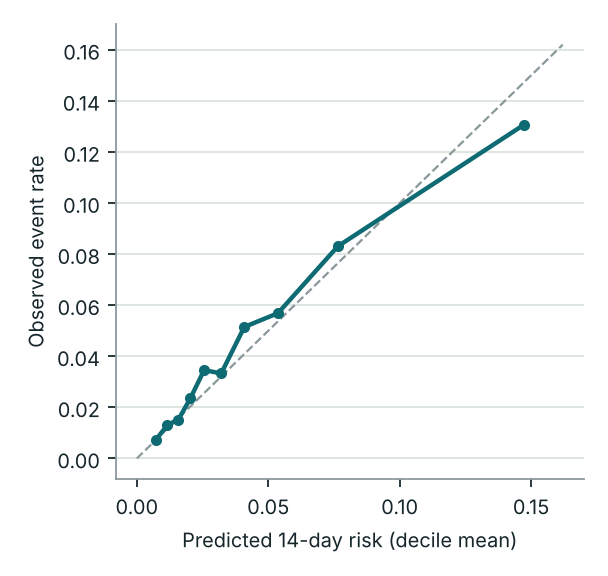

In [9]:
from IPython.display import Image, display
for f in ['model_comparison', 'twin_convergence', 'calibration']:
    display(Image(filename=str(ROOT / f'docs/figures/{f}.png'), width=520))